# Big man, light feet: Yaya Touré's height against his dribbling

Touré was 188 cm, taller than about nine in ten Premier League midfielders of his era. Tall midfielders are usually
the ones who win headers and stay in position; the ones who dribble past people are usually small.
This notebook checks whether he broke that pattern.

**Heights** come from the official squad lists on premierleague.com (one height per player, as listed there), saved in
`data/external/pl_midfielder_heights.csv`. **Dribbles** are Opta take-ons: trying to beat an opponent with the ball.
A successful dribble is the closest thing in the data to agility, but it isn't the same thing: it can't see a
turn out of pressure or a burst away from a challenge that isn't a take-on.

In [1]:
from pathlib import Path
import html

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib import font_manager

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()  # project folder
REPO = next(p for p in [ROOT, *ROOT.parents] if (p / "src" / "football_analytics").exists())  # repo root
U = REPO / "data" / "raw" / "understat"
EXT = ROOT / "data" / "external"
FIGS = ROOT / "reports" / "figures"
FIGS.mkdir(parents=True, exist_ok=True)

SKY, NAVY, GREY, DARK, MUTED, LIGHT, GOLD = "#6CABDD", "#1C2C5B", "#B4B2A9", "#2B2B2A", "#6B6A64", "#F4F2EE", "#C9A227"
SRC_PL = "Data: Premier League official stats (Opta), premierleague.com. Midfielders as listed in each club's squad"
SRC_U = "Data: Understat (via douglasbc/scraping-understat-dataset)"
for _f in (ROOT / "assets" / "fonts").glob("*.ttf"):  # Barlow, bundled with the project (SIL Open Font License)
    font_manager.fontManager.addfont(str(_f))
plt.rcParams.update({
    "font.family": "Barlow", "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight", "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": GREY,
    "axes.labelcolor": DARK, "xtick.color": DARK, "ytick.color": DARK,
})


def titles(fig, title, subtitle, source, y=1.06):
    fig.suptitle(title, x=0.01, y=y, ha="left", va="bottom", fontsize=17, fontweight="bold", color=DARK, family="Barlow Condensed")
    fig.text(0.01, y - 0.005, subtitle, ha="left", va="top", fontsize=10.5, color=MUTED)
    fig.text(0.01, -0.03, source, ha="left", va="top", fontsize=8, color=MUTED)


def season_label(s):
    """2013 -> '2013/14'"""
    return f"{s}/{str(s + 1)[-2:]}"


def load_opta(min_minutes=0):
    """Every Premier League midfielder, 2010/11 to 2017/18 (official Opta stats)."""
    d = pd.read_csv(EXT / "pl_midfielders_2010-2018.csv")
    d = d[d.timePlayed >= min_minutes].copy()
    p90 = lambda s: s / d.timePlayed * 90
    d["npg"] = d.goals - d.penaltyGoals
    d["scoring"] = p90(d.npg)                                   # non-penalty goals per 90
    d["assisting"] = p90(d.goalAssists)                         # assists per 90
    d["creating"] = p90(d.keyPassesAttemptAssists)              # chances created per 90
    d["passing"] = p90(d.successfulPassesOppositionHalf)        # completed passes in the opposition half per 90
    d["carrying"] = p90(d.successfulDribbles)                   # successful dribbles per 90
    d["defending"] = p90(d.tacklesWon + d.interceptions)        # tackles won + interceptions per 90
    d["passes90"] = p90(d.totalPasses)
    d["pass_pct"] = 1 - d.totalUnsuccessfulPassesExclCrossesAndCorners / d.totalPasses
    return d


DIMS = ["scoring", "assisting", "creating", "passing", "carrying", "defending"]
DIM_LABELS = {"scoring": "Scoring\n(non-penalty goals)", "assisting": "Assisting\n(assists)", "creating": "Creating\n(chances created)",
              "passing": "Passing\n(passes in opp. half)", "carrying": "Carrying\n(successful dribbles)",
              "defending": "Defending\n(tackles won + interceptions)"}
YAYA = "Yaya Touré"

In [2]:
H = pd.read_csv(EXT / "pl_midfielder_heights.csv")
M = load_opta(min_minutes=1800).merge(H[["id", "height_cm"]], on="id", how="left")
M["drib_att"] = M.successfulDribbles + M.unsuccessfulDribbles
M["drib_pct"] = M.successfulDribbles / M.drib_att
M["aerial"] = M.aerialDuelsWon / M.timePlayed * 90
for c in ["carrying", "passes90", "scoring", "height_cm", "aerial"]:
    M["p_" + c] = M.groupby("season")[c].rank(pct=True)
print(f"{len(M)} seasons, {M.height_cm.notna().sum()} with a height. Median height {M.height_cm.median():.0f} cm")
print("Correlation of height with: dribbles/90 %.2f, aerial duels won/90 %.2f" % (M.height_cm.corr(M.carrying), M.height_cm.corr(M.aerial)))
M.groupby(pd.cut(M.height_cm, [0, 175, 180, 184, 220], labels=["≤175", "176-180", "181-184", "185+"]), observed=True).carrying.median().round(2)

617 seasons, 617 with a height. Median height 180 cm
Correlation of height with: dribbles/90 -0.11, aerial duels won/90 0.51


height_cm
≤175       1.23
176-180    0.70
181-184    0.77
185+       0.85
Name: carrying, dtype: float64

In [3]:
M[M.name == YAYA][["season", "height_cm", "p_height_cm", "carrying", "p_carrying", "drib_pct", "p_aerial"]].round(2)

,season,height_cm,p_height_cm,carrying,p_carrying,drib_pct,p_aerial
36,2010,188,0.96,1.54,0.76,0.58,0.74
104,2011,188,0.97,1.26,0.78,0.65,0.72
177,2012,188,0.93,1.11,0.75,0.67,0.65
243,2013,188,0.91,1.29,0.70,0.75,0.57
315,2014,188,0.88,1.95,0.78,0.84,0.67
393,2015,188,0.91,2.24,0.84,0.78,0.63
473,2016,188,0.90,1.25,0.66,0.84,0.88


## 1. The rare all-rounders, by height

In [4]:
# "All-round" season: top third for dribbling AND top quarter for pass volume AND top quarter for non-penalty scoring
M["allround"] = (M.p_carrying >= 2 / 3) & (M.p_passes90 >= 0.75) & (M.p_scoring >= 0.75)
AR = M[M.allround]
tall_other = AR[(AR.height_cm >= 185) & (AR.name != YAYA)]
print(f"{len(AR)} all-round seasons; {(AR.name == YAYA).sum()} were Yaya's; other players 185 cm+: {len(tall_other)}")
AR[["season", "name", "team", "height_cm"]].sort_values("height_cm", ascending=False)

20 all-round seasons; 6 were Yaya's; other players 185 cm+: 1


,season,name,team,height_cm
587,2017,Paul Pogba,Man Utd,191
36,2010,Yaya Touré,Man City,188
177,2012,Yaya Touré,Man City,188
104,2011,Yaya Touré,Man City,188
393,2015,Yaya Touré,Man City,188
243,2013,Yaya Touré,Man City,188
315,2014,Yaya Touré,Man City,188
579,2017,Kevin De Bruyne,Man City,181
553,2017,Mesut Özil,Arsenal,180
267,2013,Mesut Özil,Arsenal,180


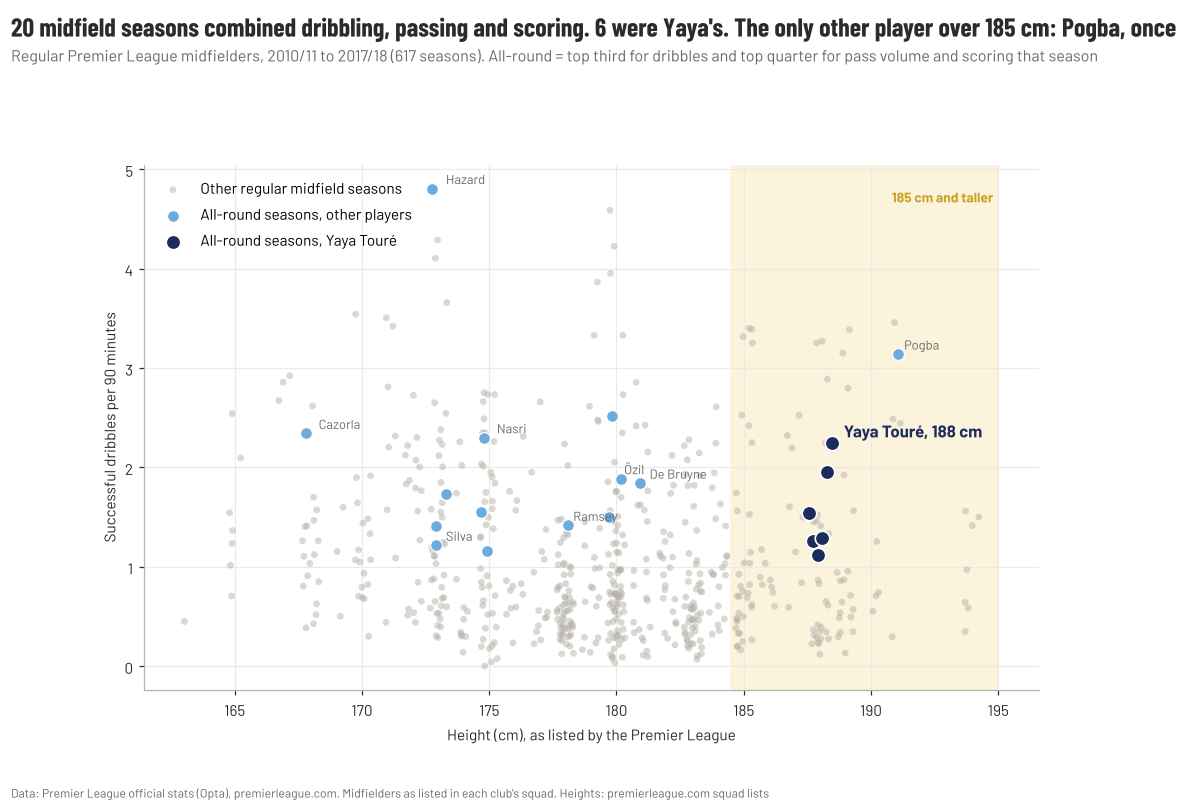

In [5]:
# Figure 9: height vs dribbles, all-round seasons highlighted
rng = np.random.default_rng(1)
jit = lambda n: rng.uniform(-0.35, 0.35, n)
fig, ax = plt.subplots(figsize=(10.5, 6.2))
base = M[~M.allround]
ax.scatter(base.height_cm + jit(len(base)), base.carrying, s=20, color=GREY, alpha=0.5, edgecolors="none", label="Other regular midfield seasons")
oth = AR[AR.name != YAYA]
ax.scatter(oth.height_cm + jit(len(oth)), oth.carrying, s=60, color=SKY, edgecolors="white", lw=0.8, zorder=3, label="All-round seasons, other players")
ya = AR[AR.name == YAYA]
ax.scatter(ya.height_cm + np.linspace(-0.45, 0.45, len(ya)), ya.carrying, s=90, color=NAVY, edgecolors="white", lw=1.1, zorder=4, label="All-round seasons, Yaya Touré")
for r in oth.drop_duplicates("name").itertuples():
    ax.annotate({"Kevin De Bruyne": "De Bruyne"}.get(r.name, r.name.split()[-1]), (r.height_cm, r.carrying), xytext=(5, 3), textcoords="offset points", fontsize=8.5, color=MUTED)
ax.annotate("Yaya Touré, 188 cm", (188.45, ya.carrying.max()), xytext=(8, 4), textcoords="offset points", fontsize=11, color=NAVY, fontweight="bold")
ax.axvspan(184.5, M.height_cm.max() + 1, color="#FBF3DC", zorder=0)
ax.text(M.height_cm.max() + 0.8, M.carrying.max(), "185 cm and taller", ha="right", va="top", fontsize=9, color=GOLD, fontweight="bold")
ax.set_xlabel("Height (cm), as listed by the Premier League"); ax.set_ylabel("Successful dribbles per 90 minutes")
ax.grid(color="#ECEAE4", lw=0.8); ax.set_axisbelow(True); ax.legend(frameon=False, loc="upper left")
titles(fig, f"{len(AR)} midfield seasons combined dribbling, passing and scoring. {len(ya)} were Yaya's. The only other player over 185 cm: Pogba, once",
       f"Regular Premier League midfielders, 2010/11 to 2017/18 ({len(M)} seasons). All-round = top third for dribbles and top quarter for pass volume and scoring that season",
       SRC_PL + ". Heights: premierleague.com squad lists")
fig.savefig(FIGS / "09_height_vs_dribbling.png")

## 2. Not just how often, but how cleanly

,season,drib_att,drib_pct,rank,n
36,2010,88,0.58,13.0,39
104,2011,57,0.65,6.0,35
177,2012,52,0.67,2.0,37
243,2013,56,0.75,4.0,39
315,2014,61,0.84,3.0,44
393,2015,74,0.78,2.0,50


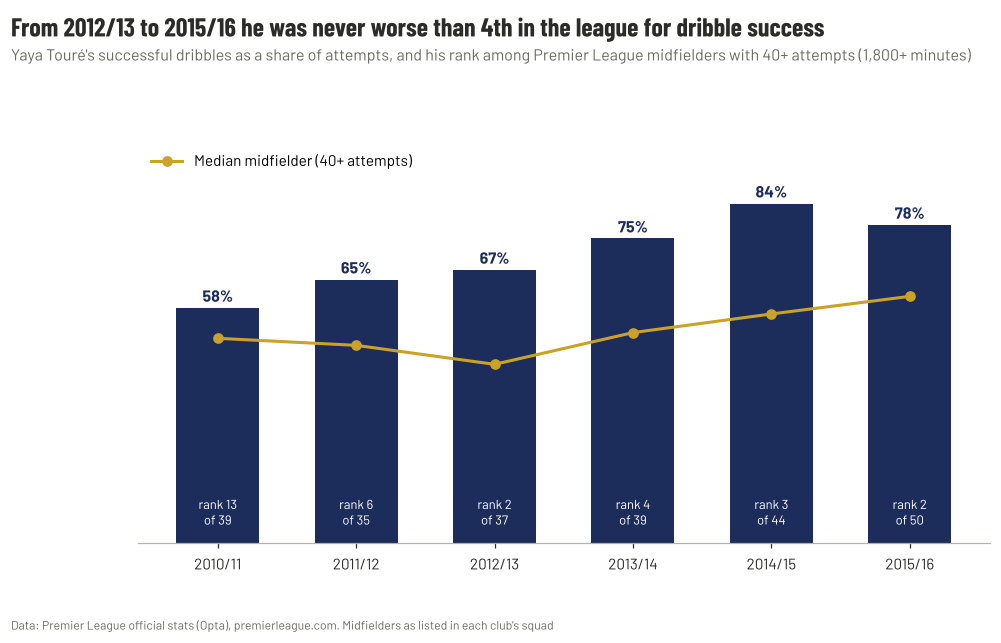

In [6]:
# Dribble success rate, midfielders with 40+ attempts in the season
D = M[M.drib_att >= 40].copy()
D["rank"] = D.groupby("season").drib_pct.rank(ascending=False, method="min")
D["n"] = D.groupby("season").drib_pct.transform("size")
yd = D[D.name == YAYA].sort_values("season")
med = D.groupby("season").drib_pct.median()
fig, ax = plt.subplots(figsize=(10, 4.8))
x = np.arange(len(yd))
ax.bar(x, yd.drib_pct * 100, width=0.6, color=NAVY)
ax.plot(x, med.loc[yd.season].values * 100, color=GOLD, lw=2, marker="o", label="Median midfielder (40+ attempts)")
for xi, r in zip(x, yd.itertuples()):
    ax.text(xi, r.drib_pct * 100 + 1.5, f"{r.drib_pct * 100:.0f}%", ha="center", fontsize=10.5, color=NAVY, fontweight="bold")
    ax.text(xi, 4, f"rank {int(r.rank)}\nof {r.n}", ha="center", va="bottom", fontsize=8.5, color="white")
ax.set_xticks(x, [season_label(s) for s in yd.season]); ax.set_ylim(0, 100); ax.set_yticks([])
ax.spines["left"].set_visible(False); ax.legend(frameon=False, loc="upper left")
best = yd[yd.season.between(2012, 2015)]
titles(fig, f"From 2012/13 to 2015/16 he was never worse than {int(best['rank'].max())}th in the league for dribble success",
       "Yaya Touré's successful dribbles as a share of attempts, and his rank among Premier League midfielders with 40+ attempts (1,800+ minutes)",
       SRC_PL)
fig.savefig(FIGS / "10_dribble_success.png")
yd[["season", "drib_att", "drib_pct", "rank", "n"]].round(2)